# IT3212 Assignment 3: Student dropout and academic support

Run this notebook from `notebooks/assignment3/`, with the repository's `requirements.txt`
installed. The input is `../../data/graduation_dataset.csv`. Numerical outputs are written
to `../../results/assignment3/` and figures to `../../figures/assignment3/`.
Use **Restart Kernel and Run All** for a reproducible run. CPU execution is supported.

The numbered sections follow the assignment PDF. All modelling choices below, including
the split, search grids and illustrative support capacity, are local experimental choices.
The brief specifies 200 points and a passing mark of 130; it does not specify a report format
or word limit. Saved outputs document one run, not a guarantee of performance elsewhere.


## 1. Develop a problem statement (real world and machine learning)

### a. Connect the machine learning problem to a real-world scenario

**Problem statement:** How can machine learning use student background information and
academic results from the first two semesters to identify students at risk of dropping out
and help academic advisors prioritize support at the end of the first academic year?

**Scenario and decision.** A higher education institution has limited capacity for individual
student support. Advisors would use a ranked list to invite students for a voluntary conversation
about academic difficulties and available support. For evaluation, assume capacity to contact
20% of students; this is an illustrative budget, not an observed institutional policy.
The output supports human review and is not used to deny admission, funding or services.

**Learning task.** Predict the three recorded statuses `Dropout`, `Enrolled`, and `Graduate`,
then use the score for `Dropout` to rank students for support. Keeping `Enrolled` separate
avoids treating students still studying as confirmed graduates. Dropout average precision
(AP) is the primary model-selection metric; macro F1 checks performance across all three
classes. Precision and recall among the top 20% translate rankings into a support workload.
AP summarizes the precision-recall curve; it is not classification accuracy.

**Data and limits.** The local file contains one row per student and background plus first-
and second-semester information. The source describes undergraduate degrees, normally three
years (four for nursing), with status recorded at the end of normal programme duration.
The current UCI release has a different feature count from this local 35-column version;
we inspect the actual local schema instead of importing a replacement.

There is no dropout date, enrolment cohort identifier or longitudinal status history in the
CSV. Some recorded dropouts may have left before the proposed intervention date. Availability
dates for administrative fields such as payment status are also unverified. Consequently,
this is a retrospective feasibility study, not a validated prospective early-warning system.
A real deployment requires a cohort still enrolled at the decision date, timestamped features,
future outcomes and an evaluation of whether support actually helps. A random student split
does not demonstrate generalization to future cohorts or other institutions. Associations and
feature scores do not establish causes of dropout.

Sources: [dataset description](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success)
and [Realinho et al. (2022), dataset article](https://doi.org/10.3390/data7110146).


## 2. Implement the preprocessing and justify the preprocessing steps

### Setup and data audit

We reuse Assignment 1's median/mode imputation, one-hot encoding, retention of plausible
extremes, optional `log1p` and standardization. Here we split **before fitting** imputation,
category discovery, skewness-based transformation or feature selection. All fitted quantities
come from the training set. Validation selects configurations; test evaluation occurs only
in section 10, after all choices have been locked.


In [1]:
from pathlib import Path
from time import perf_counter
from copy import deepcopy
import hashlib
import inspect
import json
import platform
import random
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.feature_selection import SelectPercentile, VarianceThreshold, f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEED = 42
CAPACITY = 0.20
CLASS_NAMES = ['Dropout', 'Enrolled', 'Graduate']
TARGET_MAP = {name: i for i, name in enumerate(CLASS_NAMES)}
DATA_PATH = Path('../../data/graduation_dataset.csv')
RESULTS = Path('../../results/assignment3')
FIGURES = Path('../../figures/assignment3')
assert DATA_PATH.is_file(), 'Run the notebook from notebooks/assignment3/.'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
# Keep timings comparable and prevent nested numerical libraries from oversubscribing the CPU.
thread_limits = threadpool_limits(limits=2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(DATA_PATH)
assert df.shape[1] == 35 and 'Target' in df
assert set(df['Target'].dropna()) == set(CLASS_NAMES)
audit = pd.Series({'rows': len(df), 'columns': df.shape[1],
    'missing_cells': int(df.isna().sum().sum()), 'exact_duplicate_rows': int(df.duplicated().sum())})
display(audit.to_frame('value'))
display(df.head())
display(df['Target'].value_counts().rename('students').to_frame())

NOMINAL = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nationality', "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"]
BINARY = ['Daytime/evening attendance', 'Displaced', 'Educational special needs',
    'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
NUMERIC = [c for c in df if c not in NOMINAL + BINARY + ['Target']]
COUNT_COLS = [c for c in NUMERIC if c.startswith('Curricular units') and not c.endswith('(grade)')]
assert (df[COUNT_COLS].dropna() >= 0).all().all()
assert all(set(df[c].dropna()).issubset({0, 1}) for c in BINARY)

# Remove only exact duplicate records and unusable labels, before partitioning.
clean = df.dropna(subset=['Target']).drop_duplicates().copy()
X = clean.drop(columns='Target')
y = clean['Target'].map(TARGET_MAP).astype(int)
# Exact duplicate predictors would require grouped splitting, even if labels differ.
assert not X.duplicated().any(), 'Identical predictor records require a group-aware split.'
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20,
    random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25,
    random_state=SEED, stratify=y_dev)
assert not (set(X_train.index) & set(X_val.index) or set(X_train.index) & set(X_test.index)
            or set(X_val.index) & set(X_test.index))
split_summary = pd.DataFrame({'rows': [len(X_train), len(X_val), len(X_test)],
    'role': ['fit preprocessing and models', 'choose settings and stopping epochs',
             'one final evaluation after choices are locked']}, index=['train', 'validation', 'test'])
display(split_summary)
split_ids = pd.concat([pd.DataFrame({'row_id': frame.index, 'split': name})
                      for name, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]])
split_ids.to_csv(RESULTS / 'split_membership.csv', index=False)
environment = {'python': sys.version, 'platform': platform.platform(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'torch': torch.__version__,
    'device': 'cpu', 'torch_threads': torch.get_num_threads(), 'seed': SEED,
    'data_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}
(RESULTS / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
display(pd.Series(environment).to_frame('environment'))


,value
rows,4424
columns,35
missing_cells,0
exact_duplicate_rows,0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nationality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


,students
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,rows,role
train,2654,fit preprocessing and models
validation,885,choose settings and stopping epochs
test,885,one final evaluation after choices are locked


,environment
python,"3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:..."
platform,Windows-11-10.0.26200-SP0
numpy,2.5.2
pandas,3.0.5
sklearn,1.9.0
torch,2.14.1+cpu
device,cpu
torch_threads,2
seed,42
data_sha256,c1622e34fd2cd39c93b0052da9367ad5ddaacc44a25807...


### Transformations and their justification

- **Imputation:** training medians for numeric values and modes for categorical/binary values.
  The audit determines whether imputation actually changes this file. Missing targets are not guessed.
- **Outliers:** use IQR diagnostics on meaningful numerical variables, not category codes.
  Retain plausible ages and count values; a zero grade is retained rather than automatically
  marked missing. The CSV alone does not establish the reason for each zero.
- **Encoding:** one-hot encode nominal codes; retain binary flags as 0/1. `Application order`
  is treated as an ordered numeric preference, an explicit modelling assumption.
- **Log transformation:** learn which nonnegative count columns have training skewness > 2,
  and apply `log1p` only to those columns. Compare with no log using validation data rather
  than assuming a less skewed distribution must improve classification.
- **Scaling:** standardize numerical values after optional log transformation. Leave binary
  and one-hot columns at 0/1. This helps distance/gradient-based methods; trees do not need it.
  A common representation simplifies comparisons. Unknown categories become all-zero indicators.
- **Imbalance:** preserve natural class proportions in each partition; assess AP and macro F1.
  Balanced class weights are used for the tree and SVM. No synthetic students are generated.

The 60/20/20 split supplies an explicit validation set, unlike Assignment 1's 80/20 split.
The test set is not used for plots, tuning, preprocessing decisions or feature selection.


In [3]:
class AdaptiveLog1p(TransformerMixin, BaseEstimator):
    def __init__(self, enabled=True, candidate_indices=(), skew_threshold=2.0):
        self.enabled = enabled
        self.candidate_indices = candidate_indices
        self.skew_threshold = skew_threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        skew = pd.DataFrame(X).skew().to_numpy()
        self.selected_ = np.array([i for i in self.candidate_indices
            if self.enabled and skew[i] > self.skew_threshold and np.min(X[:, i]) >= 0], dtype=int)
        return self

    def transform(self, X):
        out = np.array(X, dtype=float, copy=True)
        if self.selected_.size:
            if (out[:, self.selected_] < 0).any():
                raise ValueError('Negative value in a nonnegative count feature.')
            out[:, self.selected_] = np.log1p(out[:, self.selected_])
        return out

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def make_preprocessor(numeric_columns, use_log=True):
    extra_binary = [c for c in numeric_columns if c.startswith('zero_enrolment_')]
    numeric_columns = [c for c in numeric_columns if c not in extra_binary]
    candidates = tuple(i for i, c in enumerate(numeric_columns) if c in COUNT_COLS)
    numeric_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('log', AdaptiveLog1p(enabled=use_log, candidate_indices=candidates)),
        ('scale', StandardScaler())])
    categorical_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([
        ('numeric', numeric_pipe, numeric_columns),
        ('binary', SimpleImputer(strategy='most_frequent'), BINARY + extra_binary),
        ('nominal', categorical_pipe, NOMINAL)], remainder='drop')


def metric_summary(y_true, proba):
    y_true = np.asarray(y_true)
    proba = np.asarray(proba)
    assert proba.shape == (len(y_true), 3) and np.isfinite(proba).all()
    assert np.allclose(proba.sum(axis=1), 1, atol=1e-5)
    pred = proba.argmax(axis=1)
    dropout = y_true == 0
    n_contact = max(1, int(np.ceil(CAPACITY * len(y_true))))
    # Stable ordering makes score ties reproducible; tied students are not distinguishable by the model.
    selected = np.argsort(-proba[:, 0], kind='stable')[:n_contact]
    found = int(dropout[selected].sum())
    return {'dropout_AP': average_precision_score(dropout, proba[:, 0]),
        'macro_F1': f1_score(y_true, pred, average='macro', zero_division=0),
        'accuracy': accuracy_score(y_true, pred),
        'dropout_precision': precision_score(dropout, pred == 0, zero_division=0),
        'dropout_recall': recall_score(dropout, pred == 0, zero_division=0),
        'precision_at_20pct': found / n_contact,
        'recall_at_20pct': found / dropout.sum(), 'contacted': n_contact,
        'dropouts_contacted': found, 'other_status_contacted': n_contact - found}


q1, q3 = X_train[NUMERIC].quantile(.25), X_train[NUMERIC].quantile(.75)
iqr = q3 - q1
outlier_counts = ((X_train[NUMERIC] < q1 - 1.5 * iqr) |
                  (X_train[NUMERIC] > q3 + 1.5 * iqr)).sum()
display(outlier_counts.sort_values(ascending=False).rename('training_IQR_flags').to_frame())

log_checks = []
for log_enabled in [False, True]:
    candidate = Pipeline([('prep', make_preprocessor(NUMERIC, use_log=log_enabled)),
        ('model', KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=1))])
    candidate.fit(X_train, y_train)
    log_checks.append({'log_enabled': log_enabled, **metric_summary(y_val, candidate.predict_proba(X_val))})
log_comparison = pd.DataFrame(log_checks)
# Resolve equal AP in favour of the simpler transform.
USE_LOG = bool(log_comparison.sort_values(['dropout_AP', 'log_enabled'], ascending=[False, True]).iloc[0]['log_enabled'])
display(log_comparison[['log_enabled', 'dropout_AP', 'macro_F1']].round(4))
log_demo = make_preprocessor(NUMERIC, use_log=True).fit(X_train, y_train)
log_indices = log_demo.named_transformers_['numeric'].named_steps['log'].selected_
log_columns = [NUMERIC[i] for i in log_indices]
skew_table = pd.DataFrame({'training_skew_before': X_train[log_columns].skew(),
                           'training_skew_after': np.log1p(X_train[log_columns]).skew()})
display(skew_table.round(3))
display(Markdown(f'**Measured preprocessing choice:** log transformation is **{USE_LOG}** '
    f'in the main experiment, selected by validation dropout AP with a fixed KNN probe. '
    'This is a small diagnostic, not evidence that the same choice is optimal for every algorithm.'))
log_comparison.to_csv(RESULTS / 'log_ablation_validation.csv', index=False)


,training_IQR_flags
Curricular units 2nd sem (grade),524
Curricular units 1st sem (grade),431
Curricular units 1st sem (credited),341
Application order,331
Curricular units 2nd sem (credited),312
Age at enrollment,265
Curricular units 1st sem (enrolled),248
Curricular units 2nd sem (enrolled),221
Curricular units 1st sem (without evaluations),183
Curricular units 2nd sem (without evaluations),157


,log_enabled,dropout_AP,macro_F1
0,False,0.8266,0.6103
1,True,0.8311,0.6210


,training_skew_before,training_skew_after
Curricular units 1st sem (credited),4.289,2.846
Curricular units 1st sem (without evaluations),7.775,4.424
Curricular units 2nd sem (credited),4.763,3.070
Curricular units 2nd sem (without evaluations),8.128,4.911


**Measured preprocessing choice:** log transformation is **True** in the main experiment, selected by validation dropout AP with a fixed KNN probe. This is a small diagnostic, not evidence that the same choice is optimal for every algorithm.

## 3. Extract features and justify the methods used

Raw counts can partly reflect differences in the number of courses taken. We therefore
construct approval rates (`approved / enrolled`), proportions without evaluations and
evaluation attempts per enrolled unit for each semester. We also construct changes in
approval rate and grade, and total approved units across both semesters. These summarize
progress and change during the year, which are relevant to an advisor considering support.
Ratios are set to zero only when the denominator is zero; explicit zero-enrolment indicators
distinguish that case. Missing inputs otherwise remain missing until training-fitted imputation.

These are deterministic, per-student transformations using no target labels or other students.
They are hypothesized signals, not proven causes. Grade differences involving a zero grade
need cautious interpretation. Both semesters are available only at the end-of-year decision point.
We compare raw and engineered representations with the same KNN probe and retain engineered
features for the main study so feature selection can assess their usefulness across algorithms.


In [3]:
ENGINEERED = [f'{kind}_s{s}' for s in (1, 2)
    for kind in ('approval_rate', 'no_evaluation_rate', 'evaluation_intensity', 'zero_enrolment')]
ENGINEERED += ['approval_rate_change', 'grade_change', 'total_approved']


def extract_features(frame):
    out = frame.copy()
    for s in (1, 2):
        prefix = f'Curricular units {s}{"st" if s == 1 else "nd"} sem'
        enrolled = out[f'{prefix} (enrolled)']
        for kind, field in [('approval_rate', 'approved'),
                            ('no_evaluation_rate', 'without evaluations'),
                            ('evaluation_intensity', 'evaluations')]:
            ratio = out[f'{prefix} ({field})'] / enrolled.replace(0, np.nan)
            out[f'{kind}_s{s}'] = ratio.mask(enrolled.eq(0), 0)
        out[f'zero_enrolment_s{s}'] = enrolled.eq(0).astype(float).mask(enrolled.isna())
    out['approval_rate_change'] = out['approval_rate_s2'] - out['approval_rate_s1']
    out['grade_change'] = out['Curricular units 2nd sem (grade)'] - out['Curricular units 1st sem (grade)']
    out['total_approved'] = out['Curricular units 1st sem (approved)'] + out['Curricular units 2nd sem (approved)']
    return out


X_train_fe, X_val_fe = extract_features(X_train), extract_features(X_val)
NUMERIC_FE = NUMERIC + ENGINEERED
assert not np.isinf(X_train_fe[NUMERIC_FE].to_numpy()).any()
display(X_train_fe[ENGINEERED].describe().round(3))
feature_ablation = []
for label, train_frame, val_frame, cols in [
    ('raw', X_train, X_val, NUMERIC), ('engineered', X_train_fe, X_val_fe, NUMERIC_FE)]:
    probe = Pipeline([('prep', make_preprocessor(cols, USE_LOG)),
        ('model', KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=1))])
    probe.fit(train_frame, y_train)
    feature_ablation.append({'features': label, **metric_summary(y_val, probe.predict_proba(val_frame))})
feature_ablation = pd.DataFrame(feature_ablation).set_index('features')
display(feature_ablation[['dropout_AP', 'macro_F1', 'recall_at_20pct']].round(4))
delta = feature_ablation.loc['engineered', 'dropout_AP'] - feature_ablation.loc['raw', 'dropout_AP']
display(Markdown(f'**Measured effect:** the engineered representation changes validation dropout AP '
    f'by **{delta:+.4f}** for this KNN probe. The direction and magnitude apply to this probe and split; '
    'the following searches examine other model families.'))
feature_ablation.to_csv(RESULTS / 'feature_ablation_validation.csv')


,approval_rate_s1,no_evaluation_rate_s1,evaluation_intensity_s1,zero_enrolment_s1,approval_rate_s2,no_evaluation_rate_s2,evaluation_intensity_s2,zero_enrolment_s2,approval_rate_change,grade_change,total_approved
count,2654.000,2654.000,2654.000,2654.000,2654.000,2654.000,2654.000,2654.000,2654.000,2654.000,2654.000
mean,0.698,0.022,1.293,0.043,0.662,0.023,1.258,0.043,-0.037,-0.423,9.124
std,0.364,0.102,0.572,0.202,0.382,0.119,0.575,0.202,0.191,2.912,5.901
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-1.000,-16.143,0.000
25%,0.500,0.000,1.000,0.000,0.375,0.000,1.000,0.000,-0.004,-0.583,5.000
50%,0.833,0.000,1.200,0.000,0.833,0.000,1.167,0.000,0.000,0.000,10.000
75%,1.000,0.000,1.600,0.000,1.000,0.000,1.600,0.000,0.000,0.458,12.000
max,1.000,1.000,3.500,1.000,1.000,2.000,3.500,1.000,0.800,16.000,43.000


,dropout_AP,macro_F1,recall_at_20pct
features,,,
raw,0.8311,0.6210,0.5634
engineered,0.8412,0.6446,0.5669


**Measured effect:** the engineered representation changes validation dropout AP by **+0.0101** for this KNN probe. The direction and magnitude apply to this probe and split; the following searches examine other model families.

## 4. Select features or use a dimensionality reduction mechanism and justify the methods used

We remove training-constant columns, then rank the remaining columns by the ANOVA F-score
across the three target classes. This inexpensive supervised filter retains identifiable
features, unlike PCA components that mix many inputs. Its scores measure univariate
association; they do not establish causality or capture all interactions, and correlated
features may receive similar scores. We use the ranking without interpreting p-values.

The model searches compare the top **50%** with **100%** of nonconstant features. Keeping
100% is a control for information lost by filtering. Both ranking and constant detection
are fitted on training data only; the retained proportion is selected on validation AP.
PCA is therefore not required here. The neural experiments use preprocessed original
features directly, as explicitly allowed in point 9.


,feature,F_score
20,numeric__approval_rate_s2,1274.472883
17,numeric__approval_rate_s1,836.779861
11,numeric__Curricular units 2nd sem (approved),805.329921
12,numeric__Curricular units 2nd sem (grade),681.249744
25,numeric__total_approved,662.725486
5,numeric__Curricular units 1st sem (approved),472.591289
6,numeric__Curricular units 1st sem (grade),405.244109
30,binary__Tuition fees up to date,314.942585
32,binary__Scholarship holder,135.055529
29,binary__Debtor,94.156567


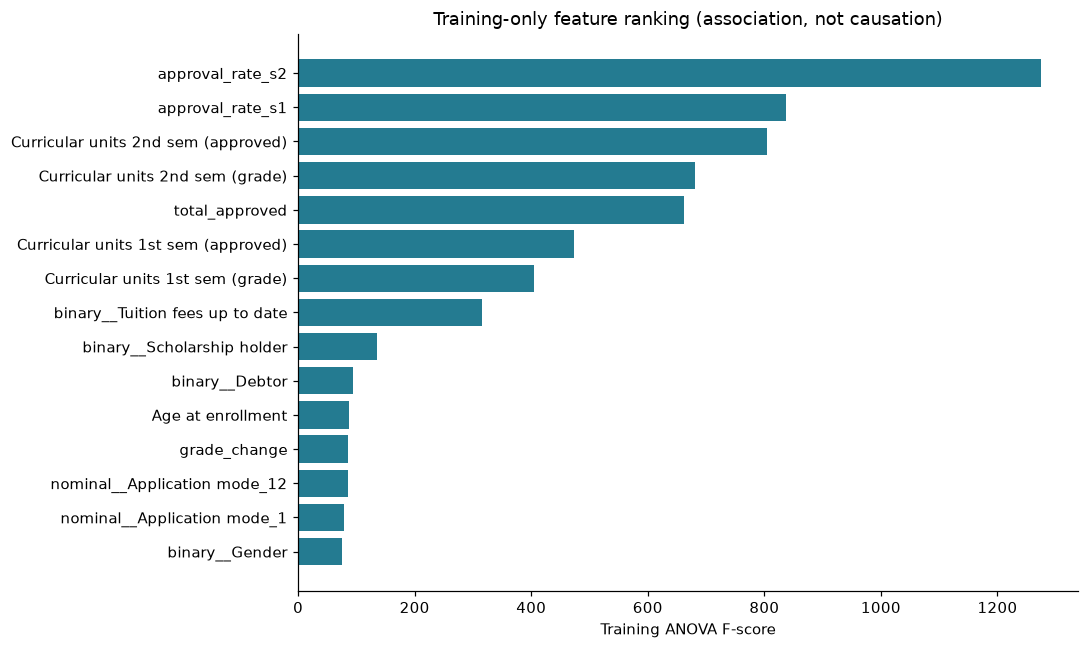

In [4]:
def finite_f_scores(X, y):
    with np.errstate(divide='ignore', invalid='ignore'):
        scores, _ = f_classif(X, y)
    return np.nan_to_num(scores, nan=0.0, posinf=1e12, neginf=0.0)


def make_pipeline(model, percentile=100):
    return Pipeline([('prep', make_preprocessor(NUMERIC_FE, USE_LOG)),
        ('nonconstant', VarianceThreshold()),
        ('select', SelectPercentile(score_func=finite_f_scores, percentile=percentile)),
        ('model', model)])


ranking_prep = make_preprocessor(NUMERIC_FE, USE_LOG)
ranking_matrix = ranking_prep.fit_transform(X_train_fe, y_train)
nonconstant = VarianceThreshold().fit(ranking_matrix)
ranking_names = ranking_prep.get_feature_names_out()[nonconstant.get_support()]
ranking_scores = finite_f_scores(nonconstant.transform(ranking_matrix), y_train)
feature_ranking = pd.DataFrame({'feature': ranking_names, 'F_score': ranking_scores}).sort_values('F_score', ascending=False)
display(feature_ranking.head(20))
feature_ranking.to_csv(RESULTS / 'training_feature_ranking.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 6))
top = feature_ranking.head(15).iloc[::-1]
ax.barh(top['feature'].str.replace('numeric__', '', regex=False), top['F_score'], color='#247b91')
ax.set(xlabel='Training ANOVA F-score', title='Training-only feature ranking (association, not causation)')
fig.tight_layout()
fig.savefig(FIGURES / '01_feature_ranking.png', dpi=160)
plt.show()


## 5. Implement three algorithms and justify the choice

### a. K-nearest neighbours

KNN is a local similarity baseline: students with similar attributes vote on the status.
It exposes whether nearby students share outcomes. We tune neighbour count (5, 15, 31)
and uniform versus distance-weighted voting. Its limitations include high-dimensional
distances and prediction cost because training examples must be stored and compared.

### d. Decision trees

A tree captures nonlinear thresholds and interactions with relatively understandable rules.
We tune maximum depth (3, 6, unlimited) and minimum leaf size (5, 20) to control overfitting.
Balanced class weights prevent the majority status from dominating every split.

### f. SVM with kernels

An RBF SVM models nonlinear class boundaries. We tune C (0.1, 1, 10) and gamma (`scale`, 0.01):
C controls the penalty for errors and gamma controls the locality of the kernel. Balanced
class weights address unequal status frequencies. `CalibratedClassifierCV` obtains out-of-fold
scores from three stratified folds within the training partition, fits sigmoid calibrators,
and refits the SVM pipeline on the full training partition (`ensemble=False`). The whole
preprocessing/selection pipeline is inside the calibrator, so each internal fold fits its own
transformations. This adds training-only calibration cost. Calibration is an estimation
procedure; its output is used for ranking and is not assumed to be perfectly calibrated risk.

Each family also compares retaining 50% versus 100% of ranked features. These are bounded
grids, not exhaustive optimization. Searches are sequential on the same CPU. AP breaks
the primary tie, macro F1 the secondary tie, and grid order resolves any exact remaining tie.
All selected models remain fitted on the 60% training partition; we do not refit on validation
data, preserving the comparison and the neural early-stopping protocol.


In [5]:
records = {}
search_tables = {}


def tune_classical(name, estimator, grid, group):
    trials, best, best_key = [], None, (-np.inf, -np.inf)
    search_start = perf_counter()
    for trial_id, params in enumerate(ParameterGrid(grid)):
        model = make_pipeline(deepcopy(estimator)).set_params(**params)
        if isinstance(estimator, SVC):
            model = CalibratedClassifierCV(estimator=model, method='sigmoid',
                cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
                ensemble=False, n_jobs=1)
        start = perf_counter()
        model.fit(X_train_fe, y_train)
        fit_seconds = perf_counter() - start
        assert np.array_equal(model.classes_, np.arange(3))
        proba = model.predict_proba(X_val_fe)
        metrics = metric_summary(y_val, proba)
        trials.append({'trial': trial_id, 'params': json.dumps(params, default=str),
                       'fit_seconds': fit_seconds, **metrics})
        key = (metrics['dropout_AP'], metrics['macro_F1'])
        if key > best_key:
            best_key = key
            best = {'model': model, 'group': group, 'fit_seconds': fit_seconds,
                    'params': params, 'val_proba': proba, 'val_metrics': metrics,
                    'representation': 'engineered'}
    best['search_seconds'] = perf_counter() - search_start
    best['trials'] = len(trials)
    records[name] = best
    search_tables[name] = pd.DataFrame(trials)
    search_tables[name].to_csv(RESULTS / f'search_{name.replace(" ", "_")}.csv', index=False)
    print(f'{name}: {len(trials)} candidates; validation AP={best_key[0]:.4f}; '
          f'search={best["search_seconds"]:.2f}s', flush=True)
    return best


dummy = make_pipeline(DummyClassifier(strategy='prior'))
start = perf_counter()
dummy.fit(X_train_fe, y_train)
dummy_fit = perf_counter() - start
dummy_p = dummy.predict_proba(X_val_fe)
records['Prior baseline'] = {'model': dummy, 'group': 'reference', 'fit_seconds': dummy_fit,
    'search_seconds': dummy_fit, 'trials': 1, 'params': {}, 'val_proba': dummy_p,
    'val_metrics': metric_summary(y_val, dummy_p), 'representation': 'engineered'}

tune_classical('KNN', KNeighborsClassifier(n_jobs=1),
    {'model__n_neighbors': [5, 15, 31], 'model__weights': ['uniform', 'distance'],
     'select__percentile': [50, 100]}, 'basic')
tune_classical('Decision tree', DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
    {'model__max_depth': [3, 6, None], 'model__min_samples_leaf': [5, 20],
     'select__percentile': [50, 100]}, 'basic')
tune_classical('RBF SVM', SVC(kernel='rbf', class_weight='balanced',
                            random_state=SEED, cache_size=512),
    {'model__C': [.1, 1., 10.], 'model__gamma': ['scale', .01],
     'select__percentile': [50, 100]}, 'basic')
display(pd.DataFrame([{'model': name, 'selected_parameters': str(records[name]['params'])}
                     for name in ['KNN', 'Decision tree', 'RBF SVM']]))


KNN: 12 candidates; validation AP=0.8488; search=2.63s


Decision tree: 12 candidates; validation AP=0.8486; search=2.38s


RBF SVM: 12 candidates; validation AP=0.8679; search=27.97s


,model,selected_parameters
0,KNN,"{'model__n_neighbors': 31, 'model__weights': '..."
1,Decision tree,"{'model__max_depth': 6, 'model__min_samples_le..."
2,RBF SVM,"{'model__C': 1.0, 'model__gamma': 0.01, 'selec..."


## 6. Compare the performance of the three algorithms with respect to the problem

This is a **validation comparison**, because the configurations were selected using this
partition. It supports development decisions; section 10 supplies the held-out test results.
The contact budget is fixed before comparing models. Argmax dropout recall answers a different
question from recall among the highest-ranked 20%: the first uses the most likely class,
whereas the second selects a fixed number of students regardless of class prediction.


**Measured comparison:** RBF SVM has the highest validation dropout AP (0.868) in this comparison, with macro F1 0.686. At the 20% support budget it identifies 164 recorded dropouts among 177 contacts (precision 92.7%; recall 57.7%). A student contacted with another recorded status is not necessarily someone who would not benefit from help; the dataset measures status, not support need.

,group,dropout_AP,macro_F1,accuracy,dropout_precision,dropout_recall,precision_at_20pct,recall_at_20pct,contacted,dropouts_contacted,other_status_contacted,fit_seconds,search_seconds,trials
model,,,,,,,,,,,,,,
RBF SVM,basic,0.8679,0.6855,0.7593,0.7812,0.7923,0.9266,0.5775,177,164,13,2.0767,27.9685,12
KNN,basic,0.8488,0.6353,0.7333,0.8377,0.6725,0.9209,0.5739,177,163,14,0.0889,2.6321,12
Decision tree,basic,0.8486,0.6906,0.7232,0.8140,0.7394,0.8814,0.5493,177,156,21,0.1308,2.3810,12


,model,nonconstant_features,retained_features,retained_engineered_features
0,KNN,230,115,"approval_rate_s1, no_evaluation_rate_s1, evalu..."
1,Decision tree,230,115,"approval_rate_s1, no_evaluation_rate_s1, evalu..."
2,RBF SVM,230,230,"approval_rate_s1, no_evaluation_rate_s1, evalu..."


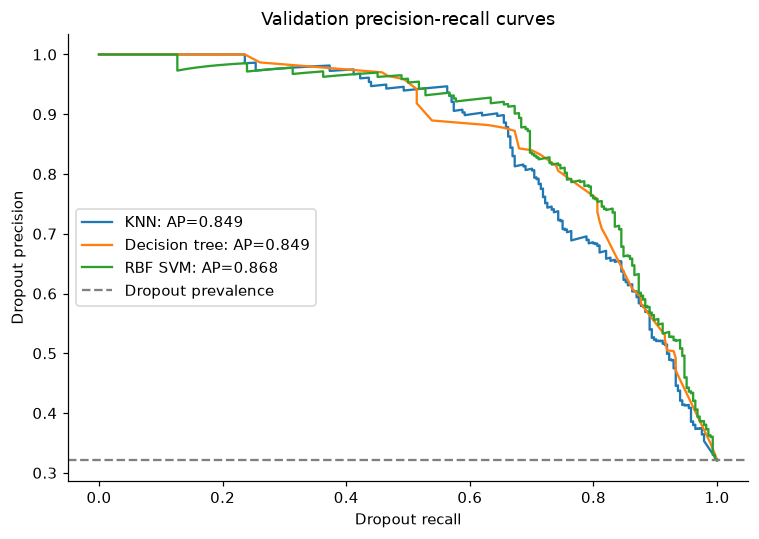

In [6]:
def validation_table(names=None):
    names = list(records) if names is None else names
    return pd.DataFrame([{'model': n, 'group': records[n]['group'],
        **records[n]['val_metrics'], 'fit_seconds': records[n]['fit_seconds'],
        'search_seconds': records[n]['search_seconds'], 'trials': records[n]['trials']}
        for n in names]).set_index('model').sort_values(['dropout_AP', 'macro_F1'], ascending=False)


def fitted_classical_pipeline(record):
    model = record['model']
    if isinstance(model, CalibratedClassifierCV):
        return model.calibrated_classifiers_[0].estimator
    return model


def explain_validation(names):
    table = validation_table(names)
    leader = table.index[0]
    r = table.iloc[0]
    display(Markdown(f'**Measured comparison:** {leader} has the highest validation dropout AP '
        f'({r.dropout_AP:.3f}) in this comparison, with macro F1 {r.macro_F1:.3f}. '
        f'At the 20% support budget it identifies {int(r.dropouts_contacted)} recorded dropouts '
        f'among {int(r.contacted)} contacts (precision {r.precision_at_20pct:.1%}; '
        f'recall {r.recall_at_20pct:.1%}). '
        'A student contacted with another recorded status is not necessarily someone who would '
        'not benefit from help; the dataset measures status, not support need.'))
    return table


basic_names = ['KNN', 'Decision tree', 'RBF SVM']
basic_table = explain_validation(basic_names)
display(basic_table.round(4))
basic_table.to_csv(RESULTS / 'basic_validation_metrics.csv')
selection_rows = []
for name in basic_names:
    fitted = fitted_classical_pipeline(records[name])
    names = fitted.named_steps['prep'].get_feature_names_out()
    names = names[fitted.named_steps['nonconstant'].get_support()]
    selected_names = names[fitted.named_steps['select'].get_support()]
    selection_rows.append({'model': name, 'nonconstant_features': len(names),
        'retained_features': len(selected_names),
        'retained_engineered_features': ', '.join(c for c in ENGINEERED
            if f'numeric__{c}' in selected_names or f'binary__{c}' in selected_names)})
    pd.Series(selected_names, name='feature').to_csv(RESULTS / f'selected_{name.replace(" ", "_")}.csv', index=False)
display(pd.DataFrame(selection_rows))
fig, ax = plt.subplots(figsize=(7, 5))
for name in basic_names:
    precision, recall, _ = precision_recall_curve(y_val == 0, records[name]['val_proba'][:, 0])
    ax.plot(recall, precision, label=f'{name}: AP={records[name]["val_metrics"]["dropout_AP"]:.3f}')
ax.axhline((y_val == 0).mean(), color='grey', linestyle='--', label='Dropout prevalence')
ax.set(xlabel='Dropout recall', ylabel='Dropout precision', title='Validation precision-recall curves')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / '02_basic_validation_pr.png', dpi=160)
plt.show()


The tree can express interactions but a small tree may miss smooth boundaries. KNN can be
affected by the many indicator dimensions even after scaling. The RBF SVM can represent
smooth nonlinear boundaries but is harder to explain. These mechanisms provide possible
interpretations; the observed ranking alone does not prove which mechanism caused a difference.
The retained-feature table records whether each model benefited from the smaller representation.


## 7. Implement boosting and bagging with different base algorithms

### Boosting: shallow decision trees with AdaBoost

1. Start with equally weighted training observations.
2. Fit a shallow tree to the current weights.
3. Increase the emphasis on misclassified observations and compute the learner's contribution.
4. Repeat, then combine the weighted class votes.

We explicitly use discrete multiclass SAMME when the installed version exposes the algorithm
argument; newer versions implement it directly. We tune tree depth (1 or 2), learning rate
(0.1 or 1.0), and number of learners (50 or 100). Learning rate controls each learner's
contribution; depth and ensemble size control capacity. The base trees do not use balanced
class weights, allowing the boosting weights to determine their sample weighting.

### Bagging: bootstrap KNN models

1. Draw a bootstrap sample of training rows for each member.
2. Select a random subset of transformed features for that member.
3. Fit an independent KNN using the neighbour count/weighting selected in section 5.
4. Average class probabilities across members.

We tune 10 or 30 members, sampling 70% or 100% of rows and 80% or 100% of features.
Bootstrap samples and feature subsets create diversity; averaging may stabilize predictions.
KNN is often already stable, so improvement is not guaranteed. This deliberately uses a
**different base algorithm** from the decision-tree boosting model, as required by the brief.
Both ensembles use all nonconstant engineered features to limit the search budget; that
representation choice is explicit. Search budgets differ from the basic models, so the
comparison concerns the tested configurations rather than an inherent ranking of algorithms.


In [7]:
boost_args = {'estimator': DecisionTreeClassifier(random_state=SEED), 'random_state': SEED}
if 'algorithm' in inspect.signature(AdaBoostClassifier).parameters:
    boost_args['algorithm'] = 'SAMME'
tune_classical('Boosted trees', AdaBoostClassifier(**boost_args),
    {'model__estimator__max_depth': [1, 2], 'model__n_estimators': [50, 100],
     'model__learning_rate': [.1, 1.]}, 'boosting')
chosen_knn = records['KNN']['model'].named_steps['model']
bagged_knn = BaggingClassifier(estimator=KNeighborsClassifier(
    n_neighbors=chosen_knn.n_neighbors, weights=chosen_knn.weights, n_jobs=1),
    bootstrap=True, random_state=SEED, n_jobs=1)
tune_classical('Bagged KNN', bagged_knn,
    {'model__n_estimators': [10, 30], 'model__max_samples': [.7, 1.],
     'model__max_features': [.8, 1.]}, 'bagging')
ensemble_comparison = validation_table(['KNN', 'Decision tree', 'Boosted trees', 'Bagged KNN'])
display(ensemble_comparison.round(4))
for ensemble, base in [('Boosted trees', 'Decision tree'), ('Bagged KNN', 'KNN')]:
    difference = records[ensemble]['val_metrics']['dropout_AP'] - records[base]['val_metrics']['dropout_AP']
    display(Markdown(f'**{ensemble}:** validation AP changes by **{difference:+.4f}** relative to '
        f'the tuned {base}. These configurations can differ in complexity and selected features; '
        'this is a practical model comparison, not a controlled isolation of ensembling alone.'))


Boosted trees: 8 candidates; validation AP=0.8847; search=8.41s


Bagged KNN: 8 candidates; validation AP=0.8505; search=6.55s


,group,dropout_AP,macro_F1,accuracy,dropout_precision,dropout_recall,precision_at_20pct,recall_at_20pct,contacted,dropouts_contacted,other_status_contacted,fit_seconds,search_seconds,trials
model,,,,,,,,,,,,,,
Boosted trees,boosting,0.8847,0.6877,0.7661,0.7748,0.8239,0.9492,0.5915,177,168,9,1.0729,8.4116,8
Bagged KNN,bagging,0.8505,0.6480,0.7424,0.8624,0.6620,0.9153,0.5704,177,162,15,0.4348,6.5490,8
KNN,basic,0.8488,0.6353,0.7333,0.8377,0.6725,0.9209,0.5739,177,163,14,0.0889,2.6321,12
Decision tree,basic,0.8486,0.6906,0.7232,0.8140,0.7394,0.8814,0.5493,177,156,21,0.1308,2.3810,12


**Boosted trees:** validation AP changes by **+0.0362** relative to the tuned Decision tree. These configurations can differ in complexity and selected features; this is a practical model comparison, not a controlled isolation of ensembling alone.

**Bagged KNN:** validation AP changes by **+0.0017** relative to the tuned KNN. These configurations can differ in complexity and selected features; this is a practical model comparison, not a controlled isolation of ensembling alone.

## 8. Compare basic, boosting, bagging and transfer approaches

### Explicit interpretation of "transfer"

The brief names transfer in point 8 without specifying a source task, dataset or pretrained
model. We implement **within-dataset transfer from reconstruction to classification**:
pretrain an autoencoder on the training predictors without labels, transfer its encoder
weights into a classifier, and fine-tune all layers using training labels. This is task
transfer through unsupervised pretraining, not evidence of transfer across institutions or
an externally pretrained model. If the course intends cross-domain transfer, that requirement
needs clarification; it cannot be inferred from the supplied one-page brief.

The source task reconstructs the preprocessed original inputs. A three-hidden-layer encoder
compresses them to a 16-dimensional representation. The target task predicts student status.
The decoder is discarded, a three-class head is added, and all encoder weights are unfrozen.
No validation or test rows are used in autoencoder training. A fixed 60 pretraining epochs
is a local choice. Reconstruction uses MSE over standardized numeric and 0/1 indicator inputs;
it may emphasize frequent or high-variance patterns rather than dropout-relevant patterns.

A matched classifier trained from random initialization uses the same architecture,
supervised seed, batches, optimizer and stopping rule. This control measures the effect of
pretraining in this experiment. The three hidden layers, learning rate 0.001 and dropout 0.1
are fixed for this pair; a separate DNN hyperparameter search follows in point 9.


In [8]:
neural_prep = make_preprocessor(NUMERIC, USE_LOG)
start = perf_counter()
Z_train = neural_prep.fit_transform(X_train, y_train).astype(np.float32)
neural_prep_seconds = perf_counter() - start
Z_val = neural_prep.transform(X_val).astype(np.float32)
assert np.isfinite(Z_train).all() and np.isfinite(Z_val).all()
train_tensor = torch.from_numpy(Z_train)
val_tensor = torch.from_numpy(Z_val)
label_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)


def seed_torch(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


class Encoder(nn.Module):
    def __init__(self, input_dim, hidden, dropout):
        super().__init__()
        layers = []
        previous = input_dim
        for width in hidden:
            layers.extend([nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)])
            previous = width
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)


class StudentNet(nn.Module):
    def __init__(self, input_dim, hidden, dropout):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden, dropout)
        self.head = nn.Linear(hidden[-1], 3)

    def forward(self, x):
        return self.head(self.encoder(x))


def neural_proba(model, array):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(torch.as_tensor(array, dtype=torch.float32)), dim=1).numpy()


def train_network(hidden=(64, 32, 16), dropout=.1, lr=.001,
                  encoder_state=None, seed=SEED, max_epochs=160, patience=18):
    seed_torch(seed)
    net = StudentNet(Z_train.shape[1], hidden, dropout)
    if encoder_state is not None:
        net.encoder.load_state_dict(encoder_state)
    # Balanced loss weights are calculated only from training labels.
    counts = np.bincount(y_train, minlength=3)
    weights = torch.tensor(len(y_train) / (3 * counts), dtype=torch.float32)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    generator = torch.Generator().manual_seed(seed)
    best_key, best_state, best_epoch, stale = (-np.inf, -np.inf), None, 0, 0
    history = []
    start = perf_counter()
    for epoch in range(1, max_epochs + 1):
        net.train()
        order = torch.randperm(len(train_tensor), generator=generator)
        loss_sum = 0.
        for indices in order.split(128):
            optimizer.zero_grad()
            loss = loss_fn(net(train_tensor[indices]), label_tensor[indices])
            loss.backward()
            optimizer.step()
            loss_sum += float(loss.detach()) * len(indices)
        proba = neural_proba(net, Z_val)
        metrics = metric_summary(y_val, proba)
        history.append({'epoch': epoch, 'train_weighted_loss': loss_sum / len(train_tensor),
            'validation_AP': metrics['dropout_AP'], 'validation_macro_F1': metrics['macro_F1']})
        key = (metrics['dropout_AP'], metrics['macro_F1'])
        if key > best_key:
            best_key, best_state, best_epoch, stale = key, deepcopy(net.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= patience:
            break
    seconds = perf_counter() - start
    net.load_state_dict(best_state)
    proba = neural_proba(net, Z_val)
    return {'model': net, 'representation': 'neural_raw', 'fit_seconds': seconds + neural_prep_seconds,
        'val_proba': proba, 'val_metrics': metric_summary(y_val, proba),
        'best_epoch': best_epoch, 'epochs_run': epoch, 'history': pd.DataFrame(history),
        'params': {'hidden': list(hidden), 'dropout': dropout, 'learning_rate': lr,
            'weight_decay': 1e-4, 'batch_size': 128, 'max_epochs': max_epochs,
            'patience': patience, 'seed': seed}, 'trials': 1, 'search_seconds': seconds + neural_prep_seconds}


seed_torch()
ae_encoder = Encoder(Z_train.shape[1], (64, 32, 16), .1)
decoder = nn.Sequential(nn.Linear(16, 32), nn.ReLU(), nn.Linear(32, 64), nn.ReLU(),
                        nn.Linear(64, Z_train.shape[1]))
autoencoder = nn.Sequential(ae_encoder, decoder)
ae_optimizer = torch.optim.AdamW(autoencoder.parameters(), lr=.001, weight_decay=1e-4)
ae_history = []
ae_generator = torch.Generator().manual_seed(SEED)
start = perf_counter()
for epoch in range(1, 61):
    autoencoder.train()
    loss_sum = 0.
    for indices in torch.randperm(len(train_tensor), generator=ae_generator).split(128):
        batch = train_tensor[indices]
        ae_optimizer.zero_grad()
        loss = nn.functional.mse_loss(autoencoder(batch), batch)
        loss.backward()
        ae_optimizer.step()
        loss_sum += float(loss.detach()) * len(indices)
    ae_history.append({'epoch': epoch, 'training_reconstruction_MSE': loss_sum / len(train_tensor)})
ae_seconds = perf_counter() - start
encoder_state = deepcopy(ae_encoder.state_dict())
for name, state in [('DNN scratch control', None), ('DNN transferred encoder', encoder_state)]:
    result = train_network(encoder_state=state)
    result['group'] = 'transfer' if state is not None else 'neural control'
    result['pretraining_seconds'] = ae_seconds if state is not None else 0.
    result['fit_seconds'] += result['pretraining_seconds']
    result['search_seconds'] += result['pretraining_seconds']
    records[name] = result
    result['history'].to_csv(RESULTS / f'history_{name.replace(" ", "_")}.csv', index=False)
    print(f'{name}: validation AP={result["val_metrics"]["dropout_AP"]:.4f}; '
          f'best epoch={result["best_epoch"]}; fit={result["fit_seconds"]:.2f}s', flush=True)
pd.DataFrame(ae_history).to_csv(RESULTS / 'autoencoder_training_history.csv', index=False)
display(pd.DataFrame(ae_history).iloc[[0, -1]])
comparison8 = explain_validation([n for n in records if n != 'Prior baseline'])
display(comparison8.round(4))
comparison8.to_csv(RESULTS / 'approaches_validation_metrics.csv')
transfer_delta = records['DNN transferred encoder']['val_metrics']['dropout_AP'] - records['DNN scratch control']['val_metrics']['dropout_AP']
display(Markdown(f'**Matched transfer experiment:** pretraining changes validation AP by '
    f'**{transfer_delta:+.4f}** and adds **{ae_seconds:.2f} s** of reconstruction training. '
    'A positive difference would support this initialization on this split; a negative difference '
    'would show that reconstruction pretraining did not help this classifier. Neither establishes '
    'a universal advantage. Different feature representations also limit direct attribution '
    'when comparing neural models with the classical models.'))


DNN scratch control: validation AP=0.8833; best epoch=9; fit=0.72s


DNN transferred encoder: validation AP=0.8860; best epoch=29; fit=20.07s


,epoch,training_reconstruction_MSE
0,1,0.131526
59,60,0.042269


**Measured comparison:** DNN transferred encoder has the highest validation dropout AP (0.886) in this comparison, with macro F1 0.734. At the 20% support budget it identifies 167 recorded dropouts among 177 contacts (precision 94.4%; recall 58.8%). A student contacted with another recorded status is not necessarily someone who would not benefit from help; the dataset measures status, not support need.

,group,dropout_AP,macro_F1,accuracy,dropout_precision,dropout_recall,precision_at_20pct,recall_at_20pct,contacted,dropouts_contacted,other_status_contacted,fit_seconds,search_seconds,trials
model,,,,,,,,,,,,,,
DNN transferred encoder,transfer,0.8860,0.7339,0.7718,0.8088,0.7746,0.9435,0.5880,177,167,10,20.0676,20.0676,1
Boosted trees,boosting,0.8847,0.6877,0.7661,0.7748,0.8239,0.9492,0.5915,177,168,9,1.0729,8.4116,8
DNN scratch control,neural control,0.8833,0.7210,0.7661,0.8043,0.7817,0.9492,0.5915,177,168,9,0.7199,0.7199,1
RBF SVM,basic,0.8679,0.6855,0.7593,0.7812,0.7923,0.9266,0.5775,177,164,13,2.0767,27.9685,12
Bagged KNN,bagging,0.8505,0.6480,0.7424,0.8624,0.6620,0.9153,0.5704,177,162,15,0.4348,6.5490,8
KNN,basic,0.8488,0.6353,0.7333,0.8377,0.6725,0.9209,0.5739,177,163,14,0.0889,2.6321,12
Decision tree,basic,0.8486,0.6906,0.7232,0.8140,0.7394,0.8814,0.5493,177,156,21,0.1308,2.3810,12


**Matched transfer experiment:** pretraining changes validation AP by **+0.0027** and adds **18.75 s** of reconstruction training. A positive difference would support this initialization on this split; a negative difference would show that reconstruction pretraining did not help this classifier. Neither establishes a universal advantage. Different feature representations also limit direct attribution when comparing neural models with the classical models.

## 9. Implement a deep Neural Network with hyperparameter tuning

A fully connected DNN is appropriate for tabular predictors. A CNN would impose spatial
neighbourhoods on an arbitrary column order, so it is not chosen. The DNN uses preprocessed
original columns, without hand-engineered features or ANOVA filtering, as allowed by the brief.

We search eight configurations: three hidden layers of **(64, 32, 16)** or **(128, 64, 32)**,
learning rate **0.001** or **0.0003**, and dropout **0.0** or **0.2**. Width controls capacity,
learning rate controls optimization steps, and dropout controls regularization. AdamW weight
decay is fixed at 0.0001 and batch size at 128 to bound the search. Weighted cross entropy
uses training class frequencies. Early stopping monitors validation dropout AP, with macro
F1 as a tie-breaker, patience 18, and a maximum of 160 epochs. The best checkpoint is restored.
These are three hidden layers plus an output layer, so this is a deep rather than single-layer network.

Each candidate uses the same seed. This controls one source of variation but does not estimate
the variability across initializations. The shared validation set is reused for preprocessing,
architecture and stopping choices; it can be overfit by selection. Only the final untouched
test set estimates generalization of the completed selection procedure.


DNN candidate 1/8: AP=0.8844, epochs=26


DNN candidate 2/8: AP=0.8861, epochs=40


DNN candidate 3/8: AP=0.8816, epochs=24


DNN candidate 4/8: AP=0.8849, epochs=34


DNN candidate 5/8: AP=0.8843, epochs=34


DNN candidate 6/8: AP=0.8849, epochs=50


DNN candidate 7/8: AP=0.8829, epochs=25


DNN candidate 8/8: AP=0.8859, epochs=37


,trial,hidden,dropout,learning_rate,best_epoch,epochs_run,fit_seconds,dropout_AP,macro_F1,accuracy,dropout_precision,dropout_recall,precision_at_20pct,recall_at_20pct,contacted,dropouts_contacted,other_status_contacted
1,1,"(64, 32, 16)",0.0,0.0003,22,40,2.5812,0.8861,0.7268,0.7672,0.8655,0.7254,0.9492,0.5915,177,168,9
7,7,"(128, 64, 32)",0.2,0.0003,19,37,1.1120,0.8859,0.7269,0.7695,0.8508,0.7430,0.9322,0.5810,177,165,12
3,3,"(128, 64, 32)",0.0,0.0003,16,34,2.3682,0.8849,0.7272,0.7684,0.8340,0.7606,0.9322,0.5810,177,165,12
5,5,"(64, 32, 16)",0.2,0.0003,32,50,3.5481,0.8849,0.7193,0.7593,0.8406,0.7430,0.9492,0.5915,177,168,9
0,0,"(64, 32, 16)",0.0,0.0010,8,26,1.1761,0.8844,0.7168,0.7458,0.8537,0.7394,0.9435,0.5880,177,167,10
4,4,"(64, 32, 16)",0.2,0.0010,16,34,2.1259,0.8843,0.7266,0.7684,0.8340,0.7606,0.9548,0.5951,177,169,8
6,6,"(128, 64, 32)",0.2,0.0010,7,25,1.6970,0.8829,0.7355,0.7751,0.8803,0.7254,0.9379,0.5845,177,166,11
2,2,"(128, 64, 32)",0.0,0.0010,6,24,1.6328,0.8816,0.7182,0.7525,0.8192,0.7500,0.9435,0.5880,177,167,10


**Selected DNN:** `{'hidden': [64, 32, 16], 'dropout': 0.0, 'learning_rate': 0.0003, 'weight_decay': 0.0001, 'batch_size': 128, 'max_epochs': 160, 'patience': 18, 'seed': 42}`; best epoch **22**, validation dropout AP **0.8861**.

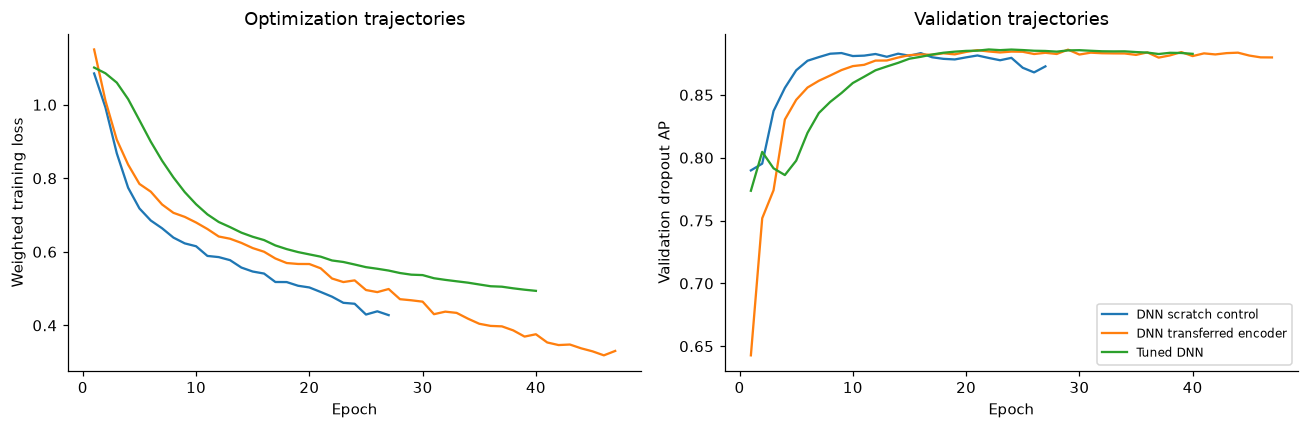

In [9]:
neural_trials = []
best_neural, best_key = None, (-np.inf, -np.inf)
search_start = perf_counter()
for trial_id, config in enumerate(ParameterGrid({'hidden': [(64, 32, 16), (128, 64, 32)],
                                                'dropout': [0., .2], 'lr': [.001, .0003]})):
    result = train_network(**config)
    neural_trials.append({'trial': trial_id, 'hidden': str(config['hidden']),
        'dropout': config['dropout'], 'learning_rate': config['lr'],
        'best_epoch': result['best_epoch'], 'epochs_run': result['epochs_run'],
        'fit_seconds': result['fit_seconds'], **result['val_metrics']})
    key = (result['val_metrics']['dropout_AP'], result['val_metrics']['macro_F1'])
    if key > best_key:
        best_key, best_neural = key, result
    print(f'DNN candidate {trial_id + 1}/8: AP={key[0]:.4f}, epochs={result["epochs_run"]}', flush=True)
best_neural.update(group='tuned deep network', search_seconds=perf_counter() - search_start + neural_prep_seconds,
                   trials=len(neural_trials), pretraining_seconds=0.)
records['Tuned DNN'] = best_neural
neural_search = pd.DataFrame(neural_trials).sort_values(['dropout_AP', 'macro_F1'], ascending=False)
display(neural_search.round(4))
neural_search.to_csv(RESULTS / 'dnn_hyperparameter_search.csv', index=False)
best_neural['history'].to_csv(RESULTS / 'tuned_dnn_history.csv', index=False)
display(Markdown(f'**Selected DNN:** `{best_neural["params"]}`; best epoch '
    f'**{best_neural["best_epoch"]}**, validation dropout AP **{best_key[0]:.4f}**.'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ['DNN scratch control', 'DNN transferred encoder', 'Tuned DNN']:
    h = records[name]['history']
    axes[0].plot(h.epoch, h.train_weighted_loss, label=name)
    axes[1].plot(h.epoch, h.validation_AP, label=name)
axes[0].set(xlabel='Epoch', ylabel='Weighted training loss', title='Optimization trajectories')
axes[1].set(xlabel='Epoch', ylabel='Validation dropout AP', title='Validation trajectories')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / '03_neural_learning_curves.png', dpi=160)
plt.show()


## 10. Compare complexity, computation time and classification performance

### Lock decisions, then evaluate the held-out test set

Before accessing test predictors or labels for evaluation, select the overall model by
validation AP, with macro F1 as a tie-breaker. The top-20% contact policy was fixed in point 1;
we do not optimize a threshold on test labels. We report every locked candidate family for
comparison, but do not switch the selected model after seeing its test result.

`fit_seconds` includes preprocessing and training of the retained configuration (and
pretraining for transfer). `search_seconds` records the whole family search including
validation inference, excluding earlier shared ablations. Neural fit time includes validation
checks during early stopping. Prediction times include preprocessing and feature extraction,
and are the median of three repeated timings on the same test batch after a warm-up. These are
local CPU wall times, not hardware-independent speed guarantees. Seeds and hardware/software
versions are saved. No learner is refitted on the test data.


In [10]:
val_all = validation_table()
eligible = val_all.drop(index='Prior baseline')
CHOSEN_MODEL = eligible.index[0]
frozen_choices = {name: {'params': item['params'], 'group': item['group'],
    'best_epoch': item.get('best_epoch'), 'representation': item['representation']}
    for name, item in records.items()}
frozen_choices['experiment'] = {'selected_model': CHOSEN_MODEL, 'selection_metric': 'validation dropout AP',
    'log_enabled': USE_LOG, 'capacity_fraction': CAPACITY, 'seed': SEED,
    'partition_sizes': {key: len(frame) for key, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]}}
(RESULTS / 'locked_choices.json').write_text(json.dumps(frozen_choices, indent=2, default=str), encoding='utf-8')
print('Model chosen before test evaluation:', CHOSEN_MODEL)


def predict_record(record, raw_frame):
    if record['representation'] == 'neural_raw':
        return neural_proba(record['model'], neural_prep.transform(raw_frame).astype(np.float32))
    return record['model'].predict_proba(extract_features(raw_frame))


def complexity_description(record):
    model = record['model']
    if record['representation'] == 'neural_raw':
        parameters = sum(p.numel() for p in model.parameters())
        return f'{parameters:,} classifier parameters; {record["epochs_run"]} epochs run'
    pipeline = fitted_classical_pipeline(record)
    estimator = pipeline.named_steps['model']
    dimensions = int(pipeline.named_steps['select'].get_support().sum())
    if isinstance(estimator, KNeighborsClassifier):
        return f'{estimator.n_samples_fit_:,} stored rows x {dimensions} features; k={estimator.n_neighbors}'
    if isinstance(estimator, DecisionTreeClassifier):
        return f'{estimator.tree_.node_count} nodes; depth {estimator.get_depth()}; {dimensions} features'
    if isinstance(estimator, SVC):
        return f'{len(estimator.support_):,} support vectors; {dimensions} features'
    if isinstance(estimator, AdaBoostClassifier):
        return f'{len(estimator.estimators_)} trees; {sum(e.tree_.node_count for e in estimator.estimators_)} total nodes'
    if isinstance(estimator, BaggingClassifier):
        return f'{len(estimator.estimators_)} KNN members; {sum(e.n_samples_fit_ for e in estimator.estimators_):,} stored row instances'
    return 'Three class-prior probabilities'


test_rows, test_probabilities = [], {}
for name, record in records.items():
    proba = predict_record(record, X_test)  # warm-up and the predictions used for evaluation
    times = []
    for _ in range(3):
        start = perf_counter()
        repeated = predict_record(record, X_test)
        times.append(perf_counter() - start)
        assert np.allclose(proba, repeated)
    test_probabilities[name] = proba
    test_rows.append({'model': name, 'group': record['group'],
        **metric_summary(y_test, proba), 'validation_AP': record['val_metrics']['dropout_AP'],
        'fit_seconds': record['fit_seconds'], 'search_seconds': record['search_seconds'],
        'prediction_ms_per_student': 1000 * np.median(times) / len(X_test),
        'complexity': complexity_description(record)})
test_results = pd.DataFrame(test_rows).set_index('model')
display(test_results.drop(columns=['complexity']).round(4))
display(test_results[['complexity']])
test_results.to_csv(RESULTS / 'final_test_metrics.csv')
val_all.to_csv(RESULTS / 'all_validation_metrics.csv')
prediction_export = pd.DataFrame({'row_id': X_test.index, 'true_status': y_test.map(dict(enumerate(CLASS_NAMES)))})
for name, proba in test_probabilities.items():
    prediction_export[f'{name}_dropout_score'] = proba[:, 0]
    prediction_export[f'{name}_predicted_status'] = [CLASS_NAMES[i] for i in proba.argmax(axis=1)]
prediction_export.to_csv(RESULTS / 'test_predictions.csv', index=False)


Model chosen before test evaluation: Tuned DNN


,group,dropout_AP,macro_F1,accuracy,dropout_precision,dropout_recall,precision_at_20pct,recall_at_20pct,contacted,dropouts_contacted,other_status_contacted,validation_AP,fit_seconds,search_seconds,prediction_ms_per_student
model,,,,,,,,,,,,,,,
Prior baseline,reference,0.3209,0.2221,0.4994,0.0000,0.0000,0.3107,0.1937,177,55,122,0.3209,0.1176,0.1176,0.0116
KNN,basic,0.8353,0.6351,0.7401,0.8348,0.6761,0.8983,0.5599,177,159,18,0.8488,0.0889,2.6321,0.0327
Decision tree,basic,0.8116,0.6609,0.6915,0.8208,0.6937,0.8701,0.5423,177,154,23,0.8486,0.1308,2.3810,0.0282
RBF SVM,basic,0.8623,0.7015,0.7706,0.7778,0.7887,0.9322,0.5810,177,165,12,0.8679,2.0767,27.9685,0.2380
Boosted trees,boosting,0.8632,0.6594,0.7435,0.7143,0.7746,0.9322,0.5810,177,165,12,0.8847,1.0729,8.4116,0.0528
Bagged KNN,bagging,0.8432,0.6057,0.7254,0.8281,0.6444,0.8983,0.5599,177,159,18,0.8505,0.4348,6.5490,1.0379
DNN scratch control,neural control,0.8786,0.7106,0.7503,0.8137,0.7535,0.9209,0.5739,177,163,14,0.8833,0.7199,0.7199,0.0146
DNN transferred encoder,transfer,0.8765,0.6948,0.7435,0.7918,0.7500,0.9266,0.5775,177,164,13,0.8860,20.0676,20.0676,0.0122
Tuned DNN,tuned deep network,0.8801,0.7034,0.7412,0.8676,0.6690,0.9266,0.5775,177,164,13,0.8861,2.5812,16.1844,0.0137


,complexity
model,
Prior baseline,Three class-prior probabilities
KNN,"2,654 stored rows x 115 features; k=31"
Decision tree,77 nodes; depth 6; 115 features
RBF SVM,"1,695 support vectors; 230 features"
Boosted trees,100 trees; 300 total nodes
Bagged KNN,"30 KNN members; 79,620 stored row instances"
DNN scratch control,"16,739 classifier parameters; 27 epochs run"
DNN transferred encoder,"16,739 classifier parameters; 47 epochs run"
Tuned DNN,"16,739 classifier parameters; 40 epochs run"


,precision,recall,f1-score,support
Dropout,0.868,0.669,0.755,284.000
Enrolled,0.430,0.654,0.519,159.000
Graduate,0.854,0.819,0.836,442.000
accuracy,0.741,0.741,0.741,0.741
macro avg,0.717,0.714,0.703,885.000
weighted avg,0.782,0.741,0.753,885.000


**Held-out result for the validation-selected model (Tuned DNN):** dropout AP **0.880** (95% test-row bootstrap interval **0.848–0.910**), macro F1 **0.703**, and accuracy **0.741**. The interval is conditional on this fitted model and assumes independent test rows; it excludes variation from training, tuning and future cohorts.

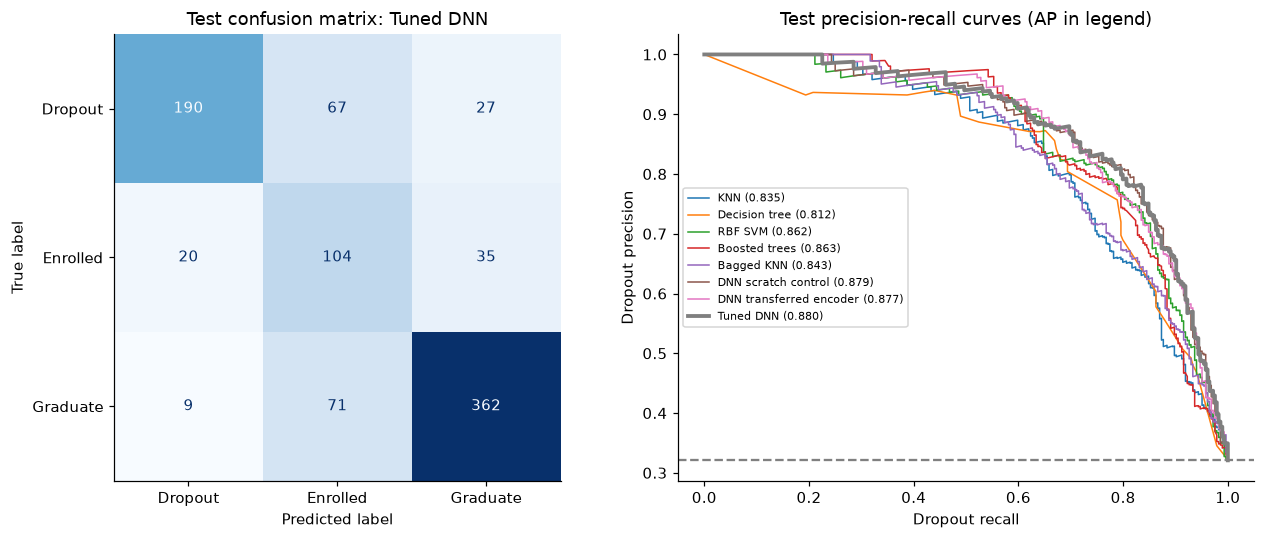

,contact_fraction,contacts,recorded_dropouts,other_statuses,precision,recall
0,0.05,45,45,0,1.000,0.158
1,0.10,89,87,2,0.978,0.306
2,0.20,177,164,13,0.927,0.577
3,0.30,266,219,47,0.823,0.771
4,0.50,443,261,182,0.589,0.919


The additional capacities are descriptive sensitivity results, not test-set tuning. The primary policy remains the predeclared 20% budget.

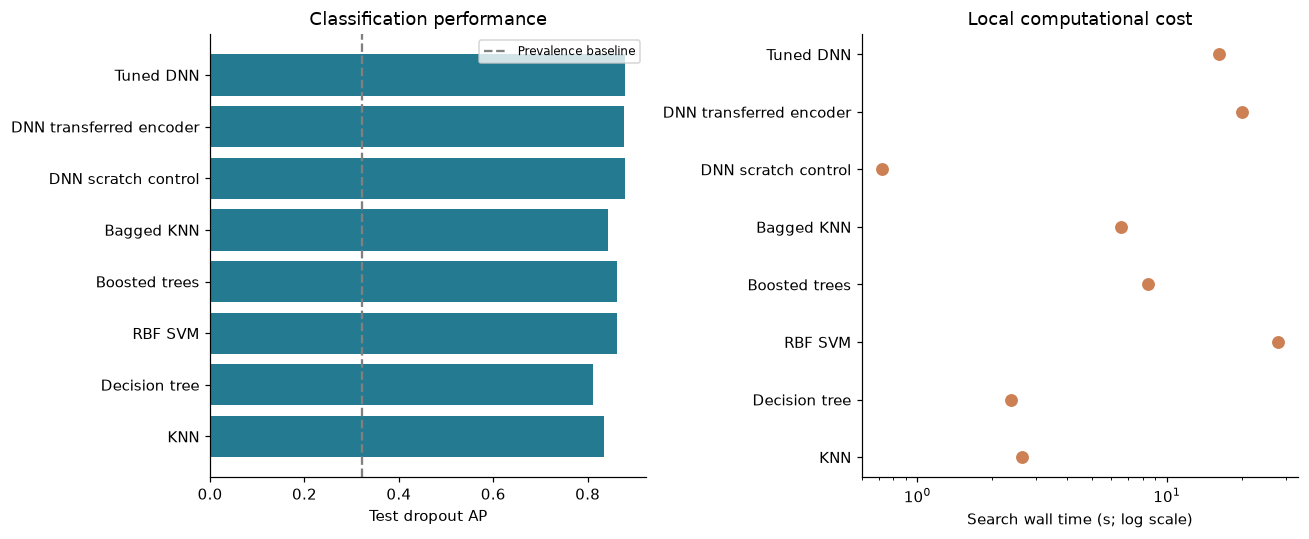

**Connection to the scenario:** the selected model would place **164 recorded dropouts** among **177 contacts**, compared with about **56.8** under random selection at the observed prevalence. It would contact **13** students with another recorded status and leave **120** recorded dropouts outside the budget. These are retrospective classifications, not counts of preventable dropouts.

**Transfer on held-out data:** the matched pretrained network changes dropout AP by **-0.0020** relative to its scratch control. The model choice remains the one locked using validation results.

**Performance and cost together:** Tuned DNN has the largest observed test AP (0.880), whereas the preselected model is Tuned DNN. Differences between the validation and test ordering illustrate sampling and selection uncertainty; the test ranking does not justify a new selection. DNN scratch control has the shortest family search (0.72 s); Bagged KNN has the largest measured prediction cost (1.038 ms per student). The trial counts and model sizes should be considered alongside these times.

**Status-level limitation:** Enrolled has the lowest recall (65.4%) for the selected model. The confusion matrix identifies which other statuses receive those predictions. This matters because a strong dropout ranking does not imply equally reliable predictions for every student status.

750

In [11]:
selected_proba = test_probabilities[CHOSEN_MODEL]
selected_pred = selected_proba.argmax(axis=1)
display(pd.DataFrame(classification_report(y_test, selected_pred, labels=[0, 1, 2],
    target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T.round(3))

# Conditional uncertainty for the fixed fitted model; it excludes training/selection variability.
rng = np.random.default_rng(SEED)
truth = y_test.to_numpy()
bootstrap_AP = []
for _ in range(1000):
    sample = rng.integers(0, len(truth), size=len(truth))
    if np.unique(truth[sample] == 0).size == 2:
        bootstrap_AP.append(average_precision_score(truth[sample] == 0, selected_proba[sample, 0]))
ap_low, ap_high = np.quantile(bootstrap_AP, [.025, .975])
selected = test_results.loc[CHOSEN_MODEL]
display(Markdown(f'**Held-out result for the validation-selected model ({CHOSEN_MODEL}):** '
    f'dropout AP **{selected.dropout_AP:.3f}** (95% test-row bootstrap interval '
    f'**{ap_low:.3f}–{ap_high:.3f}**), macro F1 **{selected.macro_F1:.3f}**, '
    f'and accuracy **{selected.accuracy:.3f}**. The interval is conditional on this fitted model '
    'and assumes independent test rows; it excludes variation from training, tuning and future cohorts.'))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, selected_pred, labels=[0, 1, 2],
    display_labels=CLASS_NAMES, cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title(f'Test confusion matrix: {CHOSEN_MODEL}')
for name in records:
    if name == 'Prior baseline':
        continue
    p, r, _ = precision_recall_curve(truth == 0, test_probabilities[name][:, 0])
    axes[1].plot(r, p, label=f'{name} ({test_results.loc[name, "dropout_AP"]:.3f})',
                 linewidth=2.5 if name == CHOSEN_MODEL else 1.)
axes[1].axhline((truth == 0).mean(), color='grey', linestyle='--')
axes[1].set(xlabel='Dropout recall', ylabel='Dropout precision', title='Test precision-recall curves (AP in legend)')
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / '04_test_classification.png', dpi=160)
plt.show()

budget_rows = []
order = np.argsort(-selected_proba[:, 0], kind='stable')
for fraction in [.05, .10, .20, .30, .50]:
    count = int(np.ceil(fraction * len(truth)))
    found = int((truth[order[:count]] == 0).sum())
    budget_rows.append({'contact_fraction': fraction, 'contacts': count, 'recorded_dropouts': found,
        'other_statuses': count - found, 'precision': found / count, 'recall': found / (truth == 0).sum()})
capacity_table = pd.DataFrame(budget_rows)
display(capacity_table.round(3))
capacity_table.to_csv(RESULTS / 'selected_model_capacity_analysis.csv', index=False)
display(Markdown('The additional capacities are descriptive sensitivity results, not test-set '
    'tuning. The primary policy remains the predeclared 20% budget.'))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_rows = test_results.drop(index='Prior baseline')
axes[0].barh(plot_rows.index, plot_rows.dropout_AP, color='#247b91')
axes[0].axvline((truth == 0).mean(), linestyle='--', color='grey', label='Prevalence baseline')
axes[0].set(xlabel='Test dropout AP', title='Classification performance')
axes[0].legend(fontsize=8)
axes[1].scatter(plot_rows.search_seconds, plot_rows.index, color='#cc8053', s=55)
axes[1].set(xlabel='Search wall time (s; log scale)', xscale='log', title='Local computational cost')
fig.tight_layout()
fig.savefig(FIGURES / '05_performance_and_time.png', dpi=160)
plt.show()

random_expected = (truth == 0).mean() * selected.contacted
transfer_test_delta = test_results.loc['DNN transferred encoder', 'dropout_AP'] - test_results.loc['DNN scratch control', 'dropout_AP']
display(Markdown(f'**Connection to the scenario:** the selected model would place '
    f'**{int(selected.dropouts_contacted)} recorded dropouts** among '
    f'**{int(selected.contacted)} contacts**, compared with about **{random_expected:.1f}** '
    f'under random selection at the observed prevalence. It would contact '
    f'**{int(selected.other_status_contacted)}** students with another recorded status and leave '
    f'**{int((truth == 0).sum() - selected.dropouts_contacted)}** recorded dropouts outside the budget. '
    'These are retrospective classifications, not counts of preventable dropouts.'))
display(Markdown(f'**Transfer on held-out data:** the matched pretrained network changes dropout AP '
    f'by **{transfer_test_delta:+.4f}** relative to its scratch control. '
    'The model choice remains the one locked using validation results.'))

observed_leader = test_results.drop(index='Prior baseline')['dropout_AP'].idxmax()
fastest_search = test_results.drop(index='Prior baseline')['search_seconds'].idxmin()
slowest_prediction = test_results.drop(index='Prior baseline')['prediction_ms_per_student'].idxmax()
display(Markdown(f'**Performance and cost together:** {observed_leader} has the largest observed '
    f'test AP ({test_results.loc[observed_leader, "dropout_AP"]:.3f}), whereas the preselected '
    f'model is {CHOSEN_MODEL}. Differences between the validation and test ordering illustrate '
    'sampling and selection uncertainty; the test ranking does not justify a new selection. '
    f'{fastest_search} has the shortest family search ({test_results.loc[fastest_search, "search_seconds"]:.2f} s); '
    f'{slowest_prediction} has the largest measured prediction cost '
    f'({test_results.loc[slowest_prediction, "prediction_ms_per_student"]:.3f} ms per student). '
    'The trial counts and model sizes should be considered alongside these times.'))
class_report = classification_report(y_test, selected_pred, labels=[0, 1, 2],
    target_names=CLASS_NAMES, output_dict=True, zero_division=0)
weakest_class = min(CLASS_NAMES, key=lambda c: class_report[c]['recall'])
display(Markdown(f'**Status-level limitation:** {weakest_class} has the lowest recall '
    f'({class_report[weakest_class]["recall"]:.1%}) for the selected model. '
    'The confusion matrix identifies which other statuses receive those predictions. '
    'This matters because a strong dropout ranking does not imply equally reliable predictions '
    'for every student status.'))

report_summary = {'selected_model': CHOSEN_MODEL, 'test_AP_bootstrap_95pct': [float(ap_low), float(ap_high)],
    'test_metrics': {k: float(v) for k, v in selected.items() if isinstance(v, (int, float, np.number))},
    'transfer_test_AP_difference': float(transfer_test_delta)}
(RESULTS / 'summary.json').write_text(json.dumps(report_summary, indent=2), encoding='utf-8')


### Complexity and interpretation

For n training students and d transformed predictors, brute-force KNN stores roughly O(nd)
values and needs O(nd) distance work per prediction. A tree stores its nodes and predicts by
following a path of length equal to its depth. Kernel SVM prediction compares a student with
its support vectors, roughly O(s d) kernel work; training is more costly than a simple tree
and includes probability estimation here. Bagging multiplies storage and prediction work
across members. Boosting sums the costs of its shallow trees. A dense DNN has a fixed number
of weights and a forward-pass cost proportional to those weights per student; pretraining
adds training cost but its decoder is discarded for inference. The concrete sizes and measured
times above make these trade-offs visible without assuming that the most complex method wins.

The preferred model is selected for dropout ranking, while macro F1 and the confusion matrix
show whether that objective neglects another status. High accuracy alone can hide errors on
the smaller `Enrolled` class. A 20% support budget also limits achievable recall: even a perfect
ranking cannot contact every dropout when dropout prevalence exceeds the budget. False
negatives can miss opportunities for support; contacts with other statuses use advisor time,
but may still be useful conversations. Capacity analysis connects these errors to workload.

The preceding numbers are specific to this split and these search budgets. Shared validation
reuse, a single random seed, lack of temporal evaluation, correlated cohort-level economic
features, and uncertain administrative timestamps limit the strength of conclusions. Student
background fields may also encode unequal historical opportunities; this analysis does not
establish fairness across demographic groups. Prospective evaluation should verify feature
availability, include only students still enrolled at the decision date, assess group-specific
errors and probability calibration, and measure the effect of actual support. No causal claim
about reducing dropout follows from classification performance alone.

### References

- Assignment brief: `../../IT3212-2026-Assignment 3.pdf` (points 1–10).
- Realinho et al. (2022). [Predicting Student Dropout and Academic Success](https://doi.org/10.3390/data7110146).
- [UCI dataset documentation](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success).
- scikit-learn: [data leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html),
  [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html),
  [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html).
- scikit-learn: [cross-validated probability calibration](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html).
- PyTorch: [neural network modules](https://docs.pytorch.org/docs/stable/nn.html).
